Connection established successfully!


C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, con)


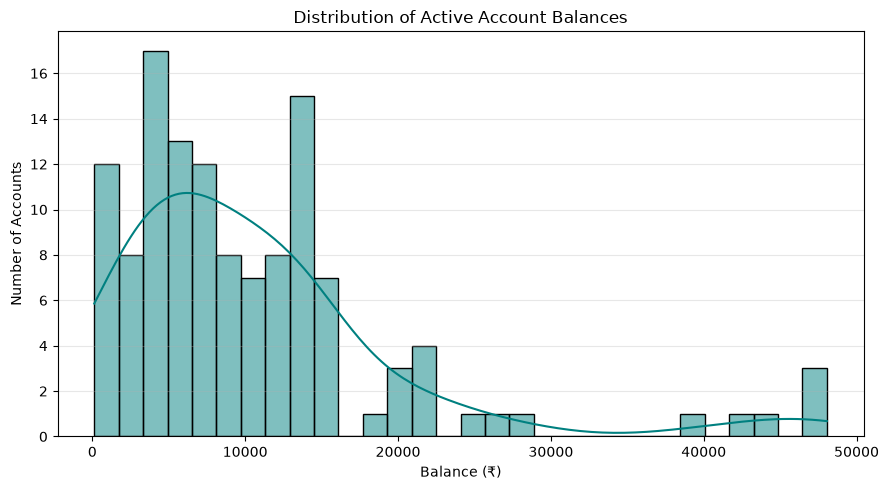

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:35: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, con)


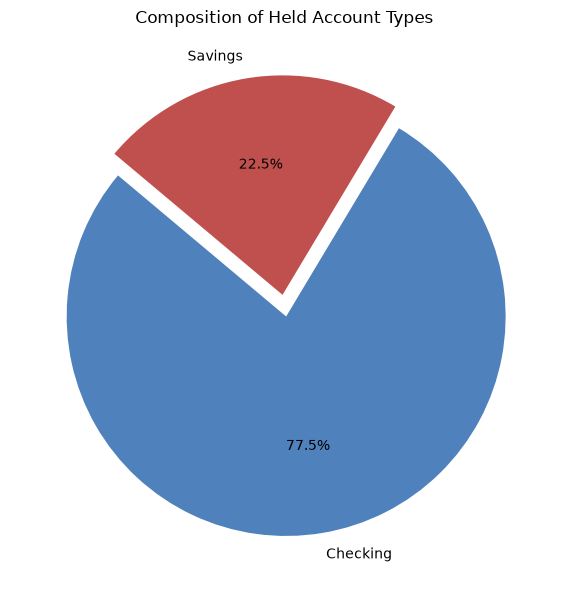

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:45: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, con)


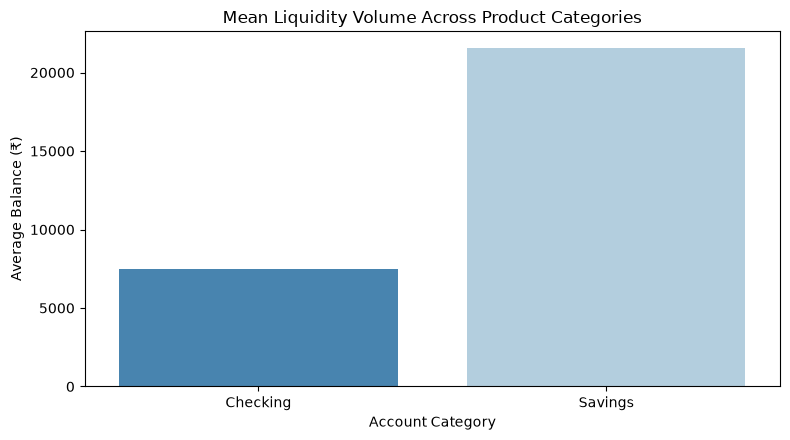

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:56: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df4 = pd.read_sql(query4, con)


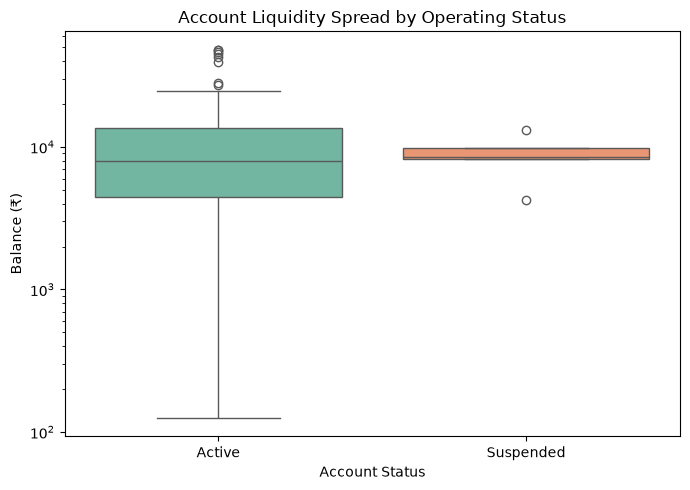

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:68: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df5 = pd.read_sql(query5, con)


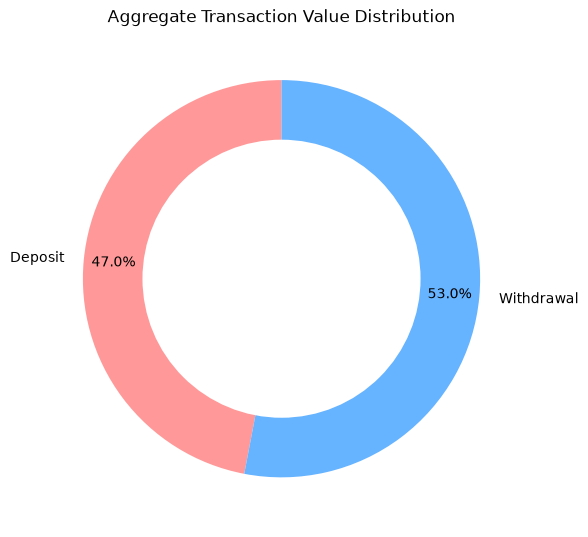

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:83: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df6 = pd.read_sql(query6, con)


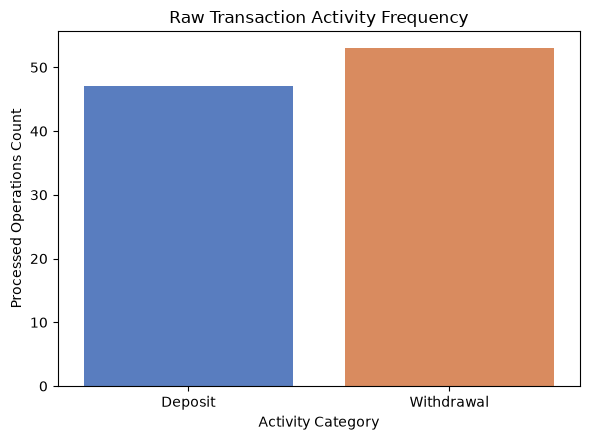

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:97: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df7 = pd.read_sql(query7, con)


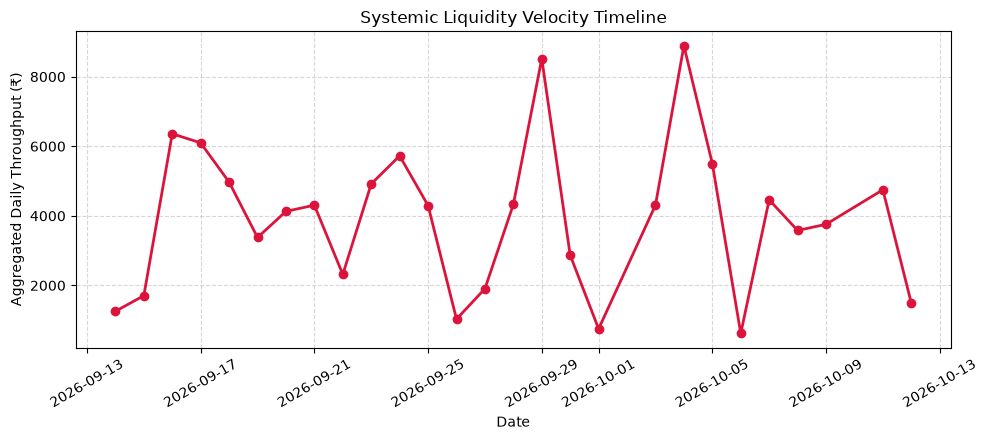

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:116: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df8 = pd.read_sql(query8, con)


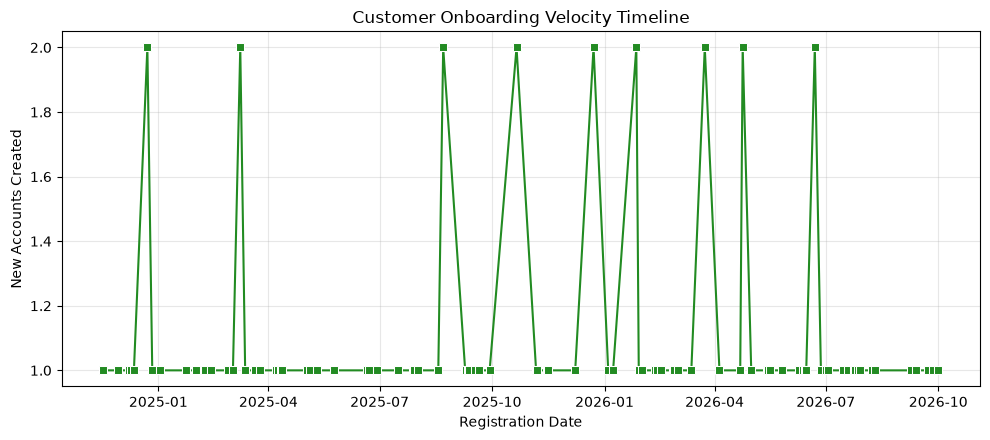

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:135: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df9 = pd.read_sql(query9, con)


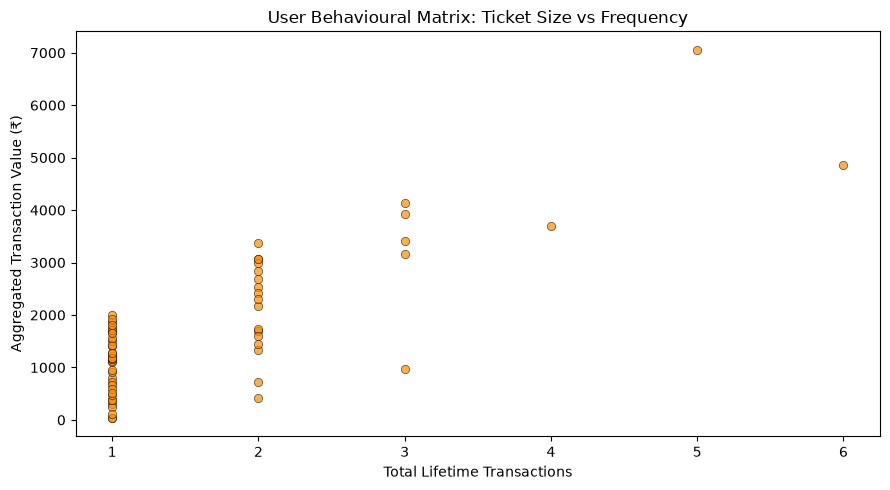

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:158: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df10 = pd.read_sql(query10, con)


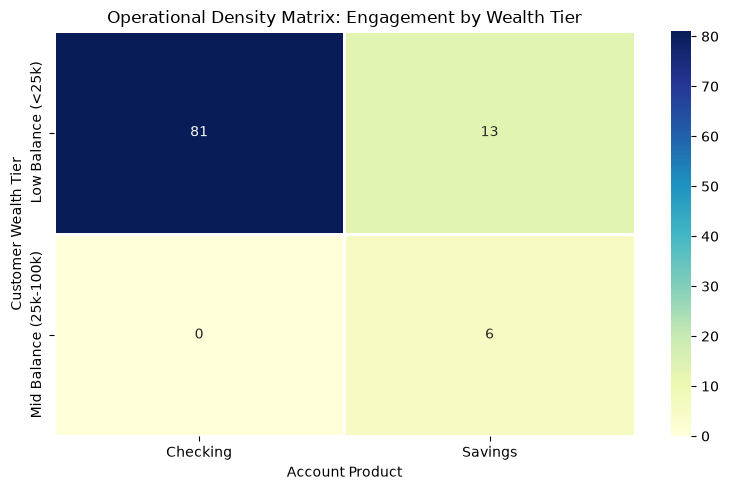

In [ ]:
import mysql.connector 

con= mysql.connector.connect(
        host="localhost",
        user="root",
        password="root",
        database="banking"
    )
print("Connection established successfully!")

cursor = con.cursor()
query = "SELECT * FROM customers"
cursor.execute(query)
results = cursor.fetchall()
# for row in results:
#     print(row)


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#seaborn histplot

query1 = "SELECT Balance FROM Accounts WHERE Status = 'Active'"
df1 = pd.read_sql(query1, con)

plt.figure(figsize=(9, 5))
sns.histplot(df1['Balance'], kde=True, color='teal', bins=30)
plt.title('Distribution of Active Account Balances')
plt.xlabel('Balance (₹)')
plt.ylabel('Number of Accounts')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

query2 = "SELECT AccountType, COUNT(*) as AccountCount FROM Accounts GROUP BY AccountType"
df2 = pd.read_sql(query2, con)

plt.figure(figsize=(6, 6))
plt.pie(df2['AccountCount'], labels=df2['AccountType'], autopct='%1.1f%%', 
        startangle=140, colors=['#4f81bd', '#c0504d', '#9bbb59'], explode=[0.05] * len(df2))
plt.title('Composition of Held Account Types')
plt.tight_layout()
plt.show()

query3 = "SELECT AccountType, AVG(Balance) as AvgBalance FROM Accounts GROUP BY AccountType"
df3 = pd.read_sql(query3, con)

plt.figure(figsize=(8, 4.5))
sns.barplot(x='AccountType', y='AvgBalance', data=df3, hue='AccountType', palette='Blues_r', legend=False)
plt.title('Mean Liquidity Volume Across Product Categories')
plt.xlabel('Account Category')
plt.ylabel('Average Balance (₹)')
plt.tight_layout()
plt.show()

query4 = "SELECT Status, Balance FROM Accounts"
df4 = pd.read_sql(query4, con)

plt.figure(figsize=(7, 5))
sns.boxplot(x='Status', y='Balance', data=df4, hue='Status', palette='Set2', legend=False)
plt.title('Account Liquidity Spread by Operating Status')
plt.xlabel('Account Status')
plt.ylabel('Balance (₹)')
plt.yscale('log')  
plt.tight_layout()
plt.show()
 
query5 = "SELECT TransactionType, SUM(Amount) as TotalVolume FROM Transactions GROUP BY TransactionType"
df5 = pd.read_sql(query5, con)

plt.figure(figsize=(6, 6))
plt.pie(df5['TotalVolume'], labels=df5['TransactionType'], autopct='%1.1f%%', 
        startangle=90, pctdistance=0.85, colors=['#ff9999','#66b3ff'])
# Create center circle to turn it into a donut chart
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Aggregate Transaction Value Distribution')
plt.tight_layout()
plt.show()

query6 = "SELECT TransactionType FROM Transactions"
df6 = pd.read_sql(query6, con)

plt.figure(figsize=(6, 4.5))
sns.countplot(x='TransactionType', data=df6, hue='TransactionType', palette='muted', legend=False)
plt.title('Raw Transaction Activity Frequency')
plt.xlabel('Activity Category')
plt.ylabel('Processed Operations Count')
plt.tight_layout()
plt.show()

query7 = """SELECT DATE(TransactionDate) as TxDate, SUM(Amount) as DailyVolume 
    FROM Transactions 
    GROUP BY DATE(TransactionDate) 
    ORDER BY TxDate"""
df7 = pd.read_sql(query7, con)
df7['TxDate'] = pd.to_datetime(df7['TxDate'])

plt.figure(figsize=(10, 4.5))
plt.plot(df7['TxDate'], df7['DailyVolume'], color='crimson', marker='o', linewidth=2)
plt.title('Systemic Liquidity Velocity Timeline')
plt.xlabel('Date')
plt.ylabel('Aggregated Daily Throughput (₹)')
plt.xticks(rotation=30)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

query8 = """
    SELECT DATE(CreatedAt) as RegDate, COUNT(CustomerID) as NewUsers 
    FROM Customers 
    GROUP BY DATE(CreatedAt) 
    ORDER BY RegDate
"""
df8 = pd.read_sql(query8, con)
df8['RegDate'] = pd.to_datetime(df8['RegDate'])

plt.figure(figsize=(10, 4.5))
sns.lineplot(x='RegDate', y='NewUsers', data=df8, color='forestgreen', marker='s')
plt.title('Customer Onboarding Velocity Timeline')
plt.xlabel('Registration Date')
plt.ylabel('New Accounts Created')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


query9 = """
    SELECT a.CustomerID, COUNT(t.TransactionID) as TxCount, SUM(t.Amount) as TotalSpent
    FROM Accounts a
    JOIN Transactions t ON a.AccountID = t.AccountID
    GROUP BY a.CustomerID
"""
df9 = pd.read_sql(query9, con)

plt.figure(figsize=(9, 5))
sns.scatterplot(x='TxCount', y='TotalSpent', data=df9, alpha=0.7, color='darkred', edgecolor='black')
plt.title('User / Customer Frequency of Transactions')
plt.xlabel('Total Lifetime Transactions')
plt.ylabel('Aggregated Transaction Value (₹)')
plt.tight_layout()
plt.show()

query10 = """
    SELECT 
        CASE 
            WHEN Balance < 25000 THEN 'Low Balance (<25k)'
            WHEN Balance BETWEEN 25000 AND 100000 THEN 'Mid Balance (25k-100k)'
            ELSE 'High Net Worth (>100k)'
        END as BalanceTier,
        AccountType,
        COUNT(t.TransactionID) as TotalTxCount
    FROM Accounts a
    LEFT JOIN Transactions t ON a.AccountID = t.AccountID
    GROUP BY BalanceTier, AccountType
"""
df10 = pd.read_sql(query10, con)

# Reshape into cross-tabulated structure for the heatmap matrix
pivot_df = df10.pivot(index='BalanceTier', columns='AccountType', values='TotalTxCount').fillna(0)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_df, annot=True, fmt=".0f", cmap='YlGnBu', linewidths=1)
plt.title('Operational Density Matrix: Engagement by Wealth Tier')
plt.xlabel('Account Product')
plt.ylabel('Customer Wealth Tier')
plt.tight_layout()
plt.show()



C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\917002589.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\917002589.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\917002589.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\917002589.py:22: UserWarning: pandas only supports S

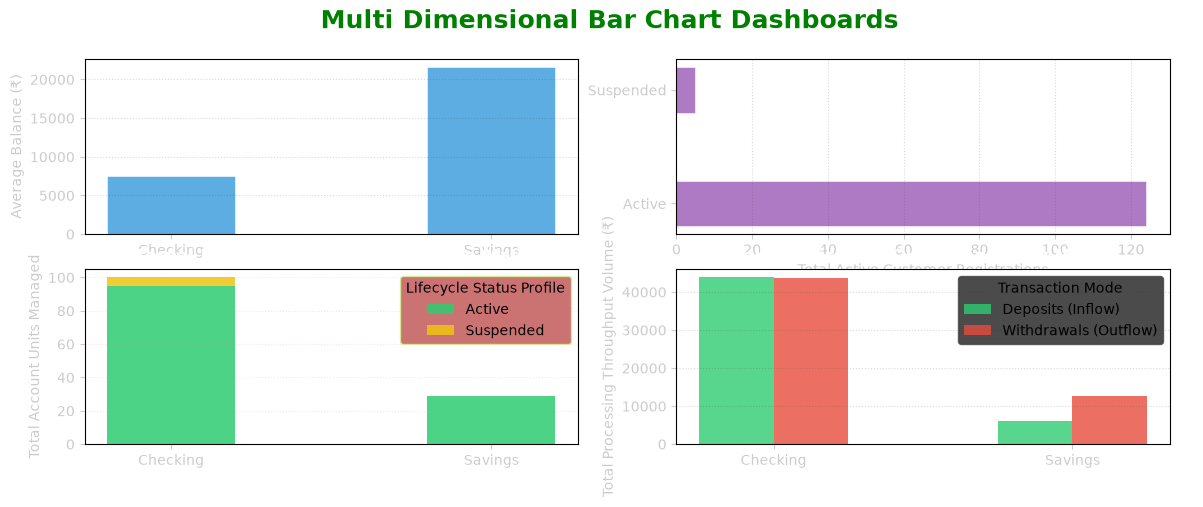

In [ ]:
#Dashboard 1 - 4 charts
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

query1 = "SELECT AccountType, AVG(Balance) as AvgBalance FROM Accounts GROUP BY AccountType"
df1 = pd.read_sql(query1, con)
    
query2 = "SELECT Status, COUNT(*) as AccountCount FROM Accounts GROUP BY Status"
df2 = pd.read_sql(query2, con)
    
query3 = "SELECT AccountType, Status, COUNT(*) as Count FROM Accounts GROUP BY AccountType, Status"
df3 = pd.read_sql(query3, con)
pivot_df3 = df3.pivot(index='AccountType', columns='Status', values='Count').fillna(0)

query4 = """
        SELECT a.AccountType, t.TransactionType, SUM(t.Amount) as TotalVolume
        FROM Accounts a
        JOIN Transactions t ON a.AccountID = t.AccountID
        GROUP BY a.AccountType, t.TransactionType
    """
df4 = pd.read_sql(query4, con)
pivot_df4 = df4.pivot(index='AccountType', columns='TransactionType', values='TotalVolume').fillna(0)


fig, axs = plt.subplots(2, 2, figsize=(14, 5))
fig.suptitle('Multi Dimensional Bar Chart Dashboards',fontsize=18,fontweight='bold',color='Green')
#char1 - Standard Bar Chart
axs[0, 0].bar(df1['AccountType'], df1['AvgBalance'], color='#3498db', alpha=0.8, width=0.4, edgecolor='#ffffff', linewidth=0.5)
axs[0, 0].set_title('Mean Liquidity Benchmarks Across Account Tiers', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 0].set_ylabel('Average Balance (₹)', color='#cccccc')
axs[0, 0].grid(axis='y', linestyle=':', alpha=0.2, color='#444444')
axs[0, 0].tick_params(colors='#cccccc')

#Horizontal Bar Chart
axs[0, 1].barh(df2['Status'], df2['AccountCount'], color='#9b59b6', alpha=0.8, height=0.4, edgecolor='#ffffff', linewidth=0.5)
axs[0, 1].set_title('Structural Account Base Distributed by Operating Status', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 1].set_xlabel('Total Active Customer Registrations', color='#cccccc')
axs[0, 1].grid(axis='x', linestyle=':', alpha=0.2, color='#444444')
axs[0, 1].tick_params(colors='#cccccc')

#stacked Bar Chart
import numpy as np
bottom_track = np.zeros(len(pivot_df3))
colors_stacked = ['#2ecc71', '#f1c40f', '#e74c3c'] # Active, Dormant, Suspended hex mapping

for i, col_name in enumerate(pivot_df3.columns):
    axs[1, 0].bar(pivot_df3.index, pivot_df3[col_name], bottom=bottom_track, 
                  label=col_name, color=colors_stacked[i % len(colors_stacked)], alpha=0.85, width=0.4)
    bottom_track += pivot_df3[col_name].values


axs[1, 0].set_title('Internal Portfolio Lifecycle Allocation Matrix', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 0].set_ylabel('Total Account Units Managed', color='#cccccc')
axs[1, 0].legend(title="Lifecycle Status Profile", facecolor="#bf5050", edgecolor="#D2F58E")
axs[1, 0].grid(axis='y', linestyle=':', alpha=0.2, color="#E58484")
axs[1, 0].tick_params(colors='#cccccc')

x_indexes = np.arange(len(pivot_df4.index))
bar_width = 0.25

# Generate side-by-side shifts by adjusting base x coordinates manually
if 'Deposit' in pivot_df4.columns:
    axs[1, 1].bar(x_indexes - bar_width/2, pivot_df4['Deposit'], 
                  width=bar_width, label='Deposits (Inflow)', color='#2ecc71', alpha=0.8)
if 'Withdrawal' in pivot_df4.columns:
    axs[1, 1].bar(x_indexes + bar_width/2, pivot_df4['Withdrawal'], 
                  width=bar_width, label='Withdrawals (Outflow)', color='#e74c3c', alpha=0.8)

axs[1, 1].set_title('Volumetric Cash Operations Flow Matrix', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 1].set_xticks(x_indexes)
axs[1, 1].set_xticklabels(pivot_df4.index)
axs[1, 1].set_ylabel('Total Processing Throughput Volume (₹)', color='#cccccc')
axs[1, 1].legend(title="Transaction Mode", facecolor="#16c984", edgecolor="#EC4343")
axs[1, 1].grid(axis='y', linestyle=':', alpha=0.2, color="#21A8D1")
axs[1, 1].tick_params(colors='#cccccc')

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_13444\2414821556.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df5 = pd.read_sql(query5, conn)
C:\Users\DELL\AppData\Local\Temp\ipykernel_13444\2414821556.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df6 = pd.read_sql(query6, conn)
C:\Users\DELL\AppData\Local\Temp\ipykernel_13444\2414821556.py:43: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df7 = pd.read_sql(query7, conn)
C:\Users\DELL\AppData\Local\Temp\ipykernel_13444\2414821556.py:54: UserWarning: pandas only su

Line Dashboard successfully compiled and saved as 'banking_line_dashboard.png' & '.pdf'!


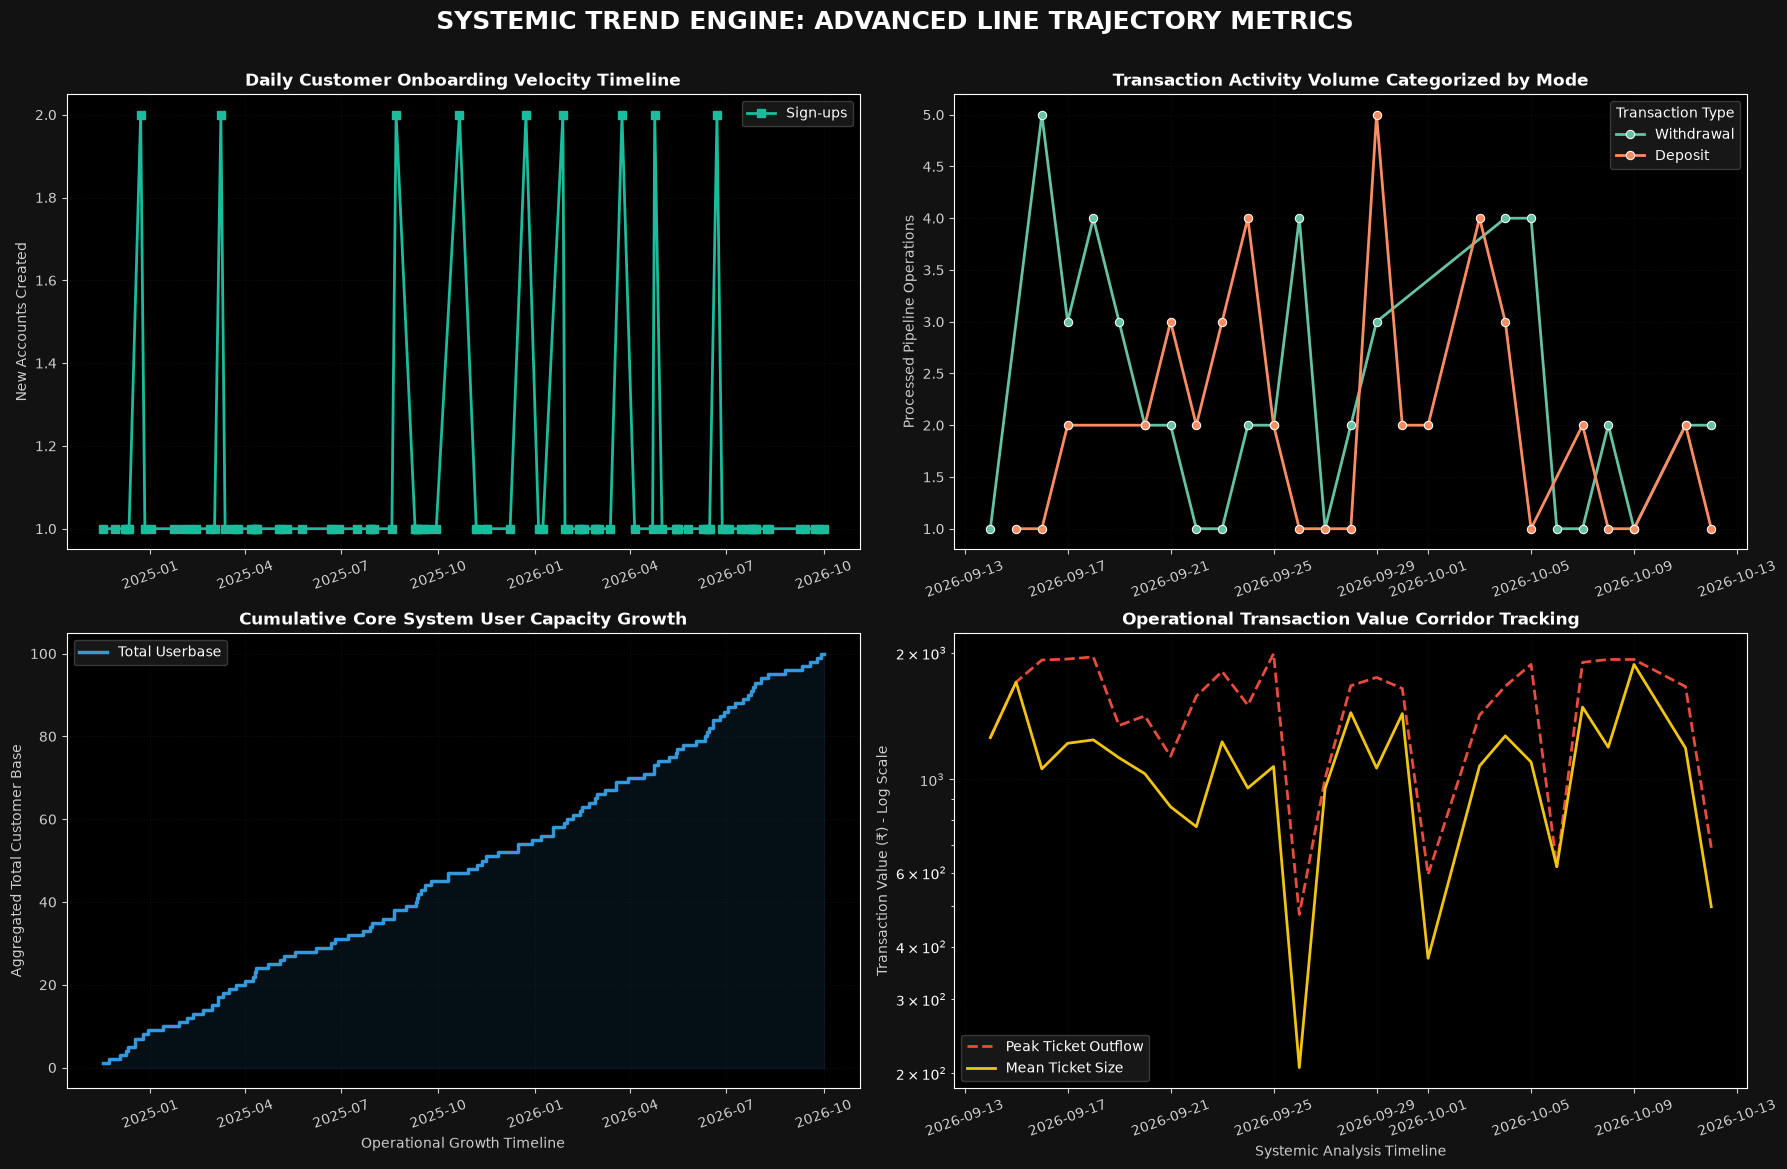

In [2]:
#Dashboard2 - 4 Charts

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector 
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="banking"
)

# Apply a professional dark dashboard theme
plt.style.use('dark_background')
query5 = """
        SELECT DATE(CreatedAt) as RegDate, COUNT(CustomerID) as NewUsers 
        FROM Customers 
        GROUP BY DATE(CreatedAt) 
        ORDER BY RegDate
    """
df5 = pd.read_sql(query5, conn)
df5['RegDate'] = pd.to_datetime(df5['RegDate'])
    
# Chart 2 - Transaction Velocity by Category
query6 ="""
        SELECT DATE(TransactionDate) as TxDate, TransactionType, COUNT(*) as TxCount
        FROM Transactions
        GROUP BY DATE(TransactionDate), TransactionType
        ORDER BY TxDate
    """
df6 = pd.read_sql(query6, conn)
df6['TxDate'] = pd.to_datetime(df6['TxDate'])

# Chart 3 - Step-Line Chart for Running Account Growth

query7 ="""
        SELECT DATE(CreatedAt) as RegDate, COUNT(*) as DailyCount
        FROM Customers
        GROUP BY DATE(CreatedAt)
        ORDER BY RegDate
    """
df7 = pd.read_sql(query7, conn)
df7['RegDate'] = pd.to_datetime(df7['RegDate'])
df7['RunningTotal'] = df7['DailyCount'].cumsum()
    
# Chart 4 Logarithmic Scale Value Trajectory
query8 ="""
        SELECT DATE(TransactionDate) as TxDate, MAX(Amount) as MaxAmount, AVG(Amount) as AvgAmount
        FROM Transactions
        GROUP BY DATE(TransactionDate)
        ORDER BY TxDate
    """
df8 = pd.read_sql(query8, conn)
df8['TxDate'] = pd.to_datetime(df8['TxDate'])

# =====================================================================
# 2. INITIALIZE UNIFIED LINE CHART DASHBOARD CANVAS (2x2 Layout)
# =====================================================================
fig, axs = plt.subplots(2, 2, figsize=(18, 12), facecolor='#121212')
fig.suptitle('SYSTEMIC TREND ENGINE: ADVANCED LINE TRAJECTORY METRICS', 
             fontsize=18, fontweight='bold', color='#ffffff', y=0.97)

# ---------------------------------------------------------------------
# CHART 1 (Top-Left | Matplotlib): Standard Single Line (User Growth)
# ---------------------------------------------------------------------
# Best for displaying a single, clean metric trend over time
axs[0, 0].plot(df5['RegDate'], df5['NewUsers'], color='#1abc9c', marker='s', markersize=6, linewidth=2, label='Sign-ups')
axs[0, 0].set_title('Daily Customer Onboarding Velocity Timeline', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 0].set_ylabel('New Accounts Created', color='#cccccc')
axs[0, 0].grid(True, linestyle=':', alpha=0.2, color='#444444')
axs[0, 0].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[0, 0].tick_params(axis='y', colors='#cccccc')
axs[0, 0].legend(facecolor='#1e1e1e', edgecolor='#444444')

# ---------------------------------------------------------------------
# CHART 2 (Top-Right | Seaborn): Multi-Series Line (Activity by Type)
# ---------------------------------------------------------------------
# Uses the 'hue' mapping to automatically break down performance parameters
sns.lineplot(
    ax=axs[0, 1], 
    x='TxDate', 
    y='TxCount', 
    hue='TransactionType', 
    data=df6, 
    marker='o', 
    linewidth=2, 
    palette='Set2'
)
axs[0, 1].set_title('Transaction Activity Volume Categorized by Mode', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 1].set_xlabel('', color='#cccccc')
axs[0, 1].set_ylabel('Processed Pipeline Operations', color='#cccccc')
axs[0, 1].grid(True, linestyle=':', alpha=0.2, color='#444444')
axs[0, 1].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[0, 1].tick_params(axis='y', colors='#cccccc')
axs[0, 1].legend(title='Transaction Type', facecolor='#1e1e1e', edgecolor='#444444')

# ---------------------------------------------------------------------
# CHART 3 (Bottom-Left | Matplotlib): Step Line Chart (Total Asset Base)
# ---------------------------------------------------------------------
# draws vertical jumps at data points instead of direct sloping angles. 
# Ideal for tracking structural inventory milestones, rates, or account totals.
axs[1, 0].step(df7['RegDate'], df7['RunningTotal'], color='#3498db', where='mid', linewidth=2.5, label='Total Userbase')
axs[1, 0].fill_between(df7['RegDate'], df7['RunningTotal'], step="mid", color="#3498db", alpha=0.1)  # Optional subtle fill
axs[1, 0].set_title('Cumulative Core System User Capacity Growth', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 0].set_xlabel('Operational Growth Timeline', color='#cccccc')
axs[1, 0].set_ylabel('Aggregated Total Customer Base', color='#cccccc')
axs[1, 0].grid(True, linestyle=':', alpha=0.2, color='#444444')
axs[1, 0].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[1, 0].tick_params(axis='y', colors='#cccccc')
axs[1, 0].legend(loc='upper left', facecolor='#1e1e1e', edgecolor='#444444')

# ---------------------------------------------------------------------
# CHART 4 (Bottom-Right | Matplotlib): Logarithmic Parallel Scale Line
# ---------------------------------------------------------------------
# Combines two related metrics while utilizing a log scale to handle massive spacing value differences cleanly.
axs[1, 1].plot(df8['TxDate'], df8['MaxAmount'], color='#e74c3c', linestyle='--', linewidth=2, label='Peak Ticket Outflow')
axs[1, 1].plot(df8['TxDate'], df8['AvgAmount'], color='#f1c40f', linestyle='-', linewidth=2, label='Mean Ticket Size')
axs[1, 1].set_title('Operational Transaction Value Corridor Tracking', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 1].set_xlabel('Systemic Analysis Timeline', color='#cccccc')
axs[1, 1].set_ylabel('Transaction Value (₹) - Log Scale', color='#cccccc')
axs[1, 1].set_yscale('log')  # Changes the vertical scaling mode to log
axs[1, 1].grid(True, linestyle=':', alpha=0.2, color='#444444')
axs[1, 1].tick_params(axis='x', rotation=20, colors='#cccccc')
axs[1, 1].tick_params(axis='y', colors='#cccccc')
axs[1, 1].legend(facecolor='#1e1e1e', edgecolor='#444444')

# =====================================================================
# 3. PACK, EXPORT ASSETS, AND SHOW
# =====================================================================
plt.tight_layout()
fig.subplots_adjust(top=0.90)

# Export the dashboard matrix directly into local directories
plt.savefig('banking_line_dashboard.png', dpi=300, facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.savefig('banking_line_dashboard.pdf', facecolor=fig.get_facecolor(), bbox_inches='tight')

print("Line Dashboard successfully compiled and saved as 'banking_line_dashboard.png' & '.pdf'!")
plt.show()
